# Week 04 ? Task 04: E-commerce review figure

One 2?2 leadership-review figure built from the cleaned traffic series and product catalogue. The figure is saved before display at 300 dpi.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.colors import LinearSegmentedColormap

DATA = Path.cwd()
if not (DATA / "sessions_hourly.csv").exists():
    DATA = Path(r"D:\University\ML Lab\Week04")
OUTPUT = DATA
plt.style.use("seaborn-v0_8-whitegrid")
COLORS = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9"]

## Required raw-file audit

These calls are intentionally run before parsing or plotting, in the assignment?s required order.

In [2]:
df = pd.read_csv(DATA / "sessions_hourly.csv")
df.info()
print("\nDESCRIBE")
print(df.describe().T)
print("\nDEVICE COUNTS")
print(df.device.value_counts())
print("\nFIRST TEN TIMESTAMPS")
print(df.ts.head(10).tolist())

<class 'pandas.DataFrame'>
RangeIndex: 12670 entries, 0 to 12669
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   ts           12670 non-null  str  
 1   sessions     12670 non-null  int64
 2   orders       12670 non-null  int64
 3   revenue_pkr  12670 non-null  int64
 4   device       12670 non-null  str  
dtypes: int64(3), str(2)
memory usage: 495.1 KB

DESCRIBE
               count           mean            std      min      25%  \
sessions     12670.0     947.951381     646.882994     -1.0    435.0   
orders       12670.0      30.016732      20.089492      4.0     14.0   
revenue_pkr  12670.0  132564.968824  100150.706234  10350.0  58036.5   

                  50%        75%        max  
sessions        756.0    1368.00     9811.0  
orders           24.0      42.00      304.0  
revenue_pkr  102359.0  182232.25  1652881.0  

DEVICE COUNTS
device
Mobile     6994
Desktop    3452
mobile      883
Tablet      777
deskto

## Cleaning rules and index audit

The raw file has six issues: `ts` is text; timestamps use two formats; device labels differ only by case; `sessions` contains `-1` sentinels; timestamps are duplicated; and the hourly index has gaps. A seventh reporting issue is the partial final month, which is excluded from the leadership series rather than treated as a full month.

In [3]:
traffic = df.copy()
traffic["device"] = traffic["device"].str.strip().str.title()
traffic["timestamp"] = pd.to_datetime(traffic["ts"], format="mixed", dayfirst=True, errors="raise")
print("Parsed range:", traffic.timestamp.min(), "to", traffic.timestamp.max())
print("Wrong default mixed parsing range would be:", pd.to_datetime(traffic.ts, format="mixed").min(), "to", pd.to_datetime(traffic.ts, format="mixed").max())
print("Negative session sentinels:", int((traffic.sessions < 0).sum()))
print("Duplicate timestamps:", int(traffic.timestamp.duplicated().sum()))

# Count missing hourly periods before resampling; resampling itself creates rows.
hourly_index = pd.DatetimeIndex(traffic.timestamp.drop_duplicates().sort_values())
expected_hourly = pd.date_range(hourly_index.min().floor("h"), hourly_index.max().ceil("h"), freq="h")
missing_hourly = expected_hourly.difference(hourly_index)
print("Missing hourly periods before resampling:", len(missing_hourly))

hourly = (
    traffic.loc[traffic["sessions"] >= 0]
    .drop_duplicates(subset="timestamp", keep="first")
    .set_index("timestamp")
    .sort_index()
)
# sum(min_count=1) retains NaN for a day with no observed hourly rows.
daily_all = hourly["sessions"].resample("D").sum(min_count=1)
complete_calendar = pd.date_range(daily_all.index.min(), daily_all.index.max(), freq="D")
daily_all = daily_all.reindex(complete_calendar)
partial_month = daily_all.index.max().to_period("M")
daily = daily_all.loc[daily_all.index.to_period("M") < partial_month].fillna(0)
print("Daily calendar gaps after reindex:", int(daily_all.isna().sum()))
print("Excluded partial final month:", partial_month)
print("Working daily range:", daily.index.min().date(), "to", daily.index.max().date())

Parsed range: 2024-01-04 00:00:00 to 2025-12-08 23:00:00
Wrong default mixed parsing range would be: 2024-01-04 01:00:00 to 2025-12-08 22:00:00
Negative session sentinels: 290
Duplicate timestamps: 921
Missing hourly periods before resampling: 5171
Daily calendar gaps after reindex: 137
Excluded partial final month: 2025-12
Working daily range: 2024-01-04 to 2025-11-30


## Catalogue cleaning

The duplicate `SKU-0127` appears twice with identical values but different parent categories; it is counted once. Negative net revenue has no area, so the seven negative rows are excluded from the hierarchy and reported separately.

In [4]:
catalogue = pd.read_csv(DATA / "revenue_catalogue.csv")
print("Catalogue rows:", len(catalogue))
print("Duplicate SKU rows:")
print(catalogue[catalogue.sku.duplicated(False)][["category", "subcategory", "sku", "net_revenue_pkr_m"]].to_string(index=False))
print("Negative net-revenue rows:", int((catalogue.net_revenue_pkr_m < 0).sum()))

catalogue_clean = catalogue.drop_duplicates(subset="sku", keep="first").copy()
negative_rows = catalogue_clean.loc[catalogue_clean["net_revenue_pkr_m"] < 0].copy()
positive_catalogue = catalogue_clean.loc[catalogue_clean["net_revenue_pkr_m"] >= 0].copy()
subcategory = positive_catalogue.groupby(["category", "subcategory"], as_index=False)["net_revenue_pkr_m"].sum()
subcategory["share_pct"] = subcategory.net_revenue_pkr_m / subcategory.net_revenue_pkr_m.sum() * 100
print("Clean hierarchy shares (%):")
print(subcategory.sort_values("net_revenue_pkr_m", ascending=False).to_string(index=False))

Catalogue rows: 345
Duplicate SKU rows:
       category subcategory      sku  net_revenue_pkr_m
Audio & Imaging       Audio SKU-0127            14.8275
      Lifestyle   Wearables SKU-0127            14.8275
Negative net-revenue rows: 7
Clean hierarchy shares (%):
       category subcategory  net_revenue_pkr_m  share_pct
         Mobile      Phones           423.7736  24.746615
      Computing     Laptops           311.9935  18.219122
Audio & Imaging       Audio           256.5434  14.981067
         Mobile Accessories           228.2380  13.328149
      Lifestyle    Footwear           188.1488  10.987107
      Lifestyle   Wearables           160.2926   9.360421
Audio & Imaging     Cameras           102.1626   5.965871
Audio & Imaging      Drones            41.2983   2.411649


## Build the 2?2 review figure

1. **Daily line:** leadership asks whether the weekly pattern obscures the trend.
2. **Heatmap:** leadership asks when sessions concentrate by weekday and hour.
3. **Treemap:** leadership asks where the category/sub-category mass is.
4. **Bars:** leadership asks by how much each sub-category differs.

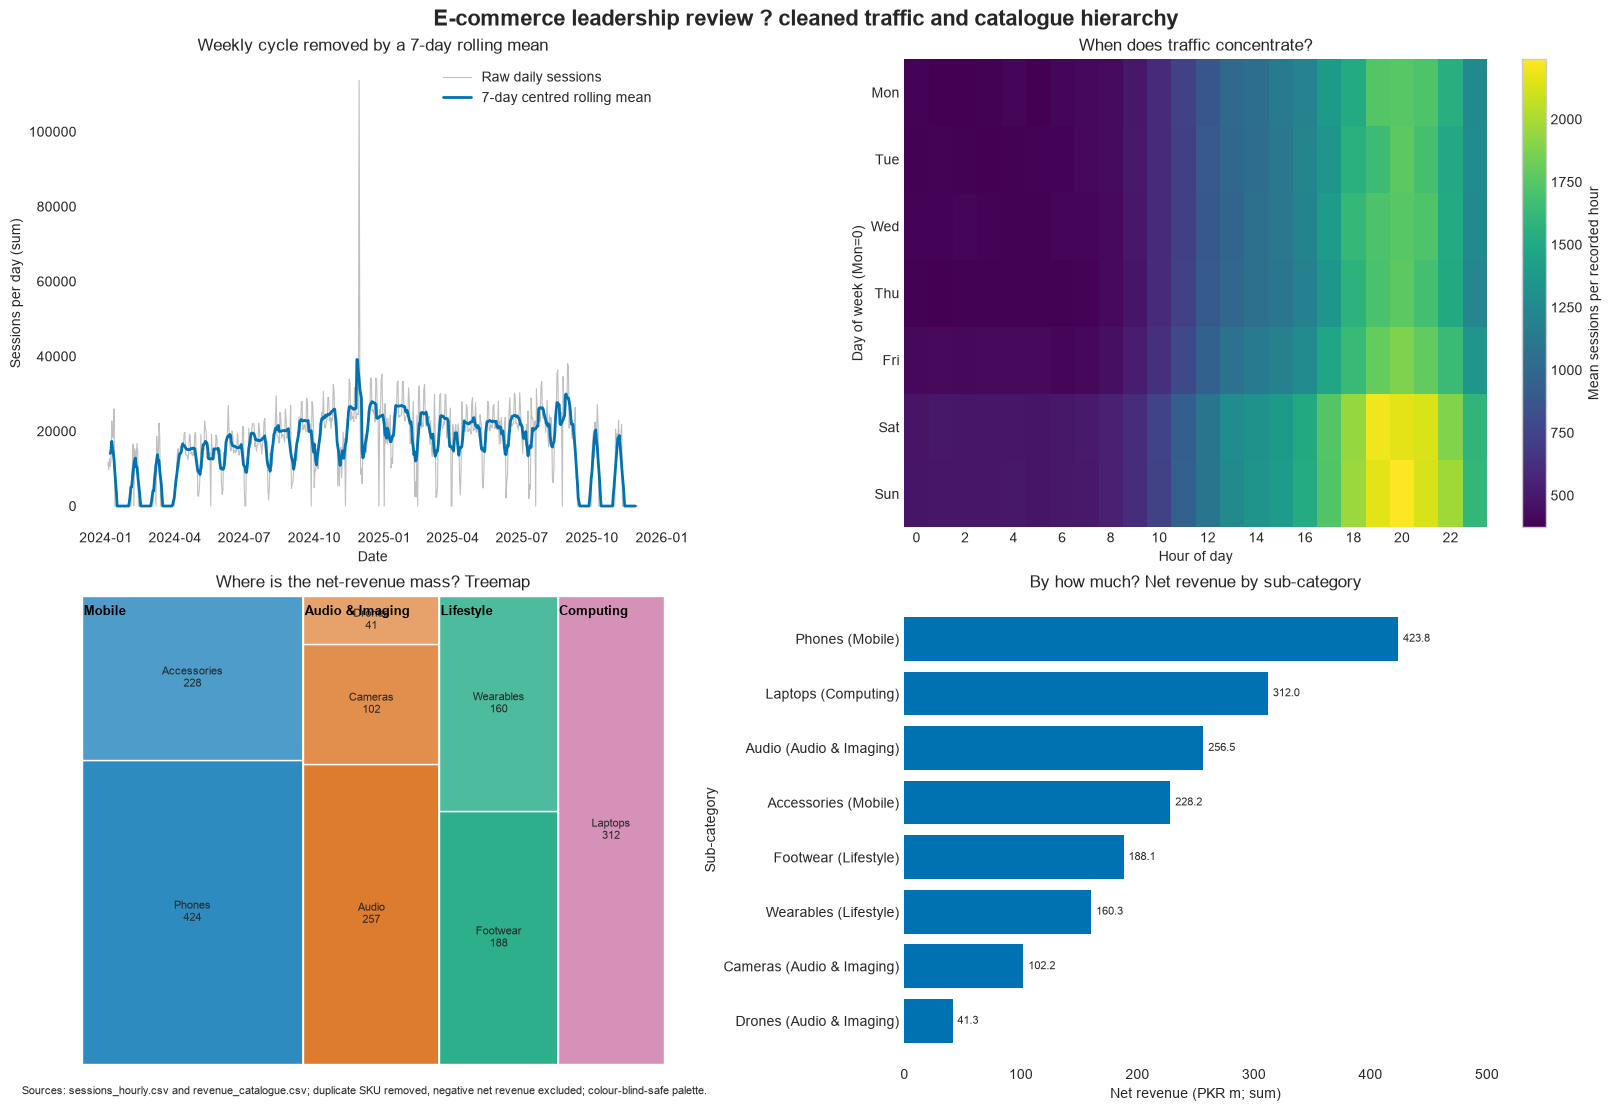

Saved: d:\University\ML Lab\Week04\task04_ecommerce_review_figure.png


In [5]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11), constrained_layout=True)
ax1, ax2, ax3, ax4 = axes.ravel()

# Panel 1: regular daily series, raw plus named smoothing window.
rolling_7 = daily.rolling(7, center=True).mean()
ax1.plot(daily.index, daily, color="0.75", linewidth=0.8, label="Raw daily sessions")
ax1.plot(rolling_7.index, rolling_7, color=COLORS[0], linewidth=2, label="7-day centred rolling mean")
ax1.set_title("Weekly cycle removed by a 7-day rolling mean")
ax1.set_xlabel("Date"); ax1.set_ylabel("Sessions per day (sum)")
ax1.legend(frameon=False)

# Panel 2: weekday ? hour mean heatmap.
hourly_clean = hourly.copy()
hourly_clean["weekday"] = hourly_clean.index.dayofweek
hourly_clean["hour"] = hourly_clean.index.hour
heat = hourly_clean.pivot_table(index="weekday", columns="hour", values="sessions", aggfunc="mean")
heat = heat.reindex(index=range(7), columns=range(24))
im = ax2.imshow(heat, aspect="auto", cmap="viridis", interpolation="nearest")
ax2.set_title("When does traffic concentrate?")
ax2.set_xlabel("Hour of day"); ax2.set_ylabel("Day of week (Mon=0)")
ax2.set_xticks(range(0, 24, 2)); ax2.set_yticks(range(7)); ax2.set_yticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
fig.colorbar(im, ax=ax2, fraction=0.046, pad=0.04, label="Mean sessions per recorded hour")

# Manual hierarchical treemap: one hue per parent category, lightness varies by sub-category.
def split_rect(x, y, w, h, values):
    total = sum(values)
    if w >= h:
        widths = [w * v / total for v in values]
        rects=[]; cursor=x
        for width in widths:
            rects.append((cursor,y,width,h)); cursor += width
        return rects
    heights = [h * v / total for v in values]
    rects=[]; cursor=y
    for height in heights:
        rects.append((x,cursor,w,height)); cursor += height
    return rects

def lighten(color, amount):
    import matplotlib.colors as mcolors
    rgb=np.array(mcolors.to_rgb(color)); return tuple(rgb + (1-rgb)*amount)

cat_totals = subcategory.groupby("category")["net_revenue_pkr_m"].sum().sort_values(ascending=False)
outer = split_rect(0, 0, 1, 1, cat_totals.tolist())
parent_colors = {cat: COLORS[i % len(COLORS)] for i, cat in enumerate(cat_totals.index)}
for (cat, total), (x,y,w,h) in zip(cat_totals.items(), outer):
    ax3.add_patch(Rectangle((x,y),w,h,facecolor=parent_colors[cat],edgecolor="white",linewidth=2))
    children = subcategory[subcategory.category.eq(cat)].sort_values("net_revenue_pkr_m", ascending=False)
    inner = split_rect(x, y, w, h, children.net_revenue_pkr_m.tolist())
    for j, (_, row) in enumerate(children.iterrows()):
        xx,yy,ww,hh=inner[j]
        ax3.add_patch(Rectangle((xx,yy),ww,hh,facecolor=lighten(parent_colors[cat], min(.65, .18+j*.12)),edgecolor="white",linewidth=1))
        if ww*hh > .018:
            ax3.text(xx+ww/2, yy+hh/2, f"{row.subcategory}\n{row.net_revenue_pkr_m:.0f}", ha="center", va="center", fontsize=8)
    ax3.text(x+w*.01, y+h*.98, cat, ha="left", va="top", fontsize=9, fontweight="bold", color="black")
ax3.set_xlim(0,1); ax3.set_ylim(0,1); ax3.axis("off")
ax3.set_title("Where is the net-revenue mass? Treemap")

# Panel 4: sorted horizontal bars, values printed.
bar = subcategory.sort_values("net_revenue_pkr_m")
bar_labels = bar["subcategory"] + " (" + bar["category"] + ")"
ax4.barh(bar_labels, bar.net_revenue_pkr_m, color=COLORS[0])
for i, value in enumerate(bar.net_revenue_pkr_m):
    ax4.text(value + subcategory.net_revenue_pkr_m.max()*.01, i, f"{value:.1f}", va="center", fontsize=8)
ax4.set_title("By how much? Net revenue by sub-category")
ax4.set_xlabel("Net revenue (PKR m; sum)"); ax4.set_ylabel("Sub-category")
ax4.set_xlim(0, bar.net_revenue_pkr_m.max()*1.18)

for ax in axes.ravel():
    ax.spines[["top", "right", "left", "bottom"]].set_visible(False)
    ax.grid(False)
fig.suptitle("E-commerce leadership review ? cleaned traffic and catalogue hierarchy", fontsize=16, fontweight="bold")
fig.text(0.01, 0.01, "Sources: sessions_hourly.csv and revenue_catalogue.csv; duplicate SKU removed, negative net revenue excluded; colour-blind-safe palette.", fontsize=8)
fig.savefig(OUTPUT / "task04_ecommerce_review_figure.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved:", OUTPUT / "task04_ecommerce_review_figure.png")

## Self-check

The cleaned eight sub-category shares should be within 0.3 percentage points of `shares_eight.csv`. The duplicate SKU is the material alternative that moves several categories by roughly 0.9 points if it is counted twice.

In [6]:
expected = pd.read_csv(DATA / "shares_eight.csv").set_index("subcategory")["share_pct"]
actual = subcategory.groupby("subcategory").share_pct.sum()
check = pd.concat([expected.rename("expected"), actual.rename("actual")], axis=1)
check["difference_pp"] = check.actual - check.expected
print(check.sort_values("actual", ascending=False).to_string())
assert check.difference_pp.abs().max() < 0.3

             expected     actual  difference_pp
subcategory                                    
Phones           24.6  24.746615       0.146615
Laptops          18.4  18.219122      -0.180878
Audio            15.0  14.981067      -0.018933
Accessories      13.1  13.328149       0.228149
Footwear         11.2  10.987107      -0.212893
Wearables         9.2   9.360421       0.160421
Cameras           6.1   5.965871      -0.134129
Drones            2.4   2.411649       0.011649
